In [1]:
!pip install -q Sastrawi datasets reportlab

In [2]:
import pandas as pd
from datasets import load_dataset

ds = load_dataset("dipawidia/ecommerce-product-reviews-sentiment")
print(ds)
df = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
df.head()

README.md:   0%|          | 0.00/1.51k [00:00<?, ?B/s]

labeledReview.datasetFix.json:   0%|          | 0.00/3.15M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11606 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['review', 'translate', 'sentimen'],
        num_rows: 11606
    })
})


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


Jumlah data : 11606
Kolom       : ['review', 'translate', 'sentimen']
review       0
translate    0
sentimen     0
dtype: int64
sentimen
0    5803
1    5803
Name: count, dtype: int64


<Axes: title={'center': 'Distribusi Sentimen'}, xlabel='sentimen'>

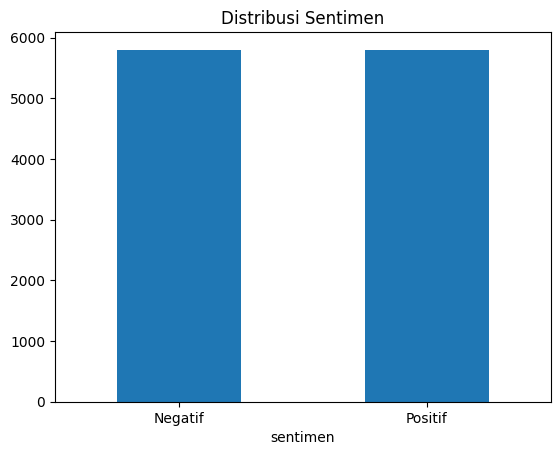

In [3]:
print("Jumlah data :", len(df))
print("Kolom       :", list(df.columns))
print(df.isna().sum())
distribusi = df["sentimen"].value_counts()
print(distribusi)
distribusi.rename({0: "Negatif", 1: "Positif"}).plot(kind="bar", rot=0, title="Distribusi Sentimen")

In [4]:
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

def lower(t):
    return str(t).lower()

def bersihkan(t):
    t = re.sub(r"http\S+|www\.\S+", " ", t)   # URL
    t = re.sub(r"[^a-z\s]", " ", t)           # angka, tanda baca, emoji
    return re.sub(r"\s+", " ", t).strip()

def pecah(t):
    return t.split()

negasi = {"tidak", "tak", "bukan", "belum", "jangan"}
stop = set(StopWordRemoverFactory().get_stop_words()) - negasi

def buang_stop(tokens):
    return [w for w in tokens if w not in stop]

stemmer = StemmerFactory().create_stemmer()
cache = {}
def stem(tokens):
    hasil = []
    for w in tokens:
        if w not in cache:
            cache[w] = stemmer.stem(w)
        hasil.append(cache[w])
    return hasil

In [5]:
df["lower"] = df["review"].apply(lower)
df["bersih"] = df["lower"].apply(bersihkan)
df["token"] = df["bersih"].apply(pecah)
df["tanpa_stop"] = df["token"].apply(buang_stop)
df["stem"] = df["tanpa_stop"].apply(stem)
df["hasil"] = df["stem"].apply(" ".join)

In [14]:
df.sample(10, random_state=7)[["review", "hasil"]]

,review,hasil
5787,liat bintangnya gak nyesel blanja disini,liat bintang gak nyesel blanja sini
10913,sesuai deskripsi and suara bagus,sesuai deskripsi and suara bagus
4542,"barang diterima baik, sesuai dengan pesanan, kemasan juga baik\nterimakasih\n",barang terima baik sesuai pesan kemas baik terimakasih
4642,Barang baggus kakkk baranfnyaa ga ada yg cacattt next akan pesan lagi.,barang baggus kakkk baranfnyaa ga yg cacattt next pesan
5340,kualitas lumayan.sesuai harga,kualitas lumayan sesuai harga
8032,"Alhamdulillah udah sampe pesen tgl 10 , bagusss 🤩🤩",alhamdulillah udah sampe sen tgl bagusss
2302,mantabhh,mantabhh
10779,Fitur Terbaik:ok\nSepadan dengan Harga:ya,fitur baik padan harga
4920,"Barang sudah di terima, tapi belum di cek performa nya seperti apa",barang terima belum cek performa nya apa
5870,"sudah sampai dengan cepat, pesan langsung proses langsung kirim, kualitas mouse bagus",cepat pesan langsung proses langsung kirim kualitas mouse bagus


In [7]:
sebelum = df["review"].str.split()
print("Vocabulary sebelum :", len(set(w for t in sebelum for w in t)))
print("Vocabulary sesudah :", len(set(w for t in df["stem"] for w in t)))
print("Rata-rata kata sebelum :", round(sebelum.apply(len).mean(), 2))
print("Rata-rata kata sesudah :", round(df["stem"].apply(len).mean(), 2))
print("Ulasan kosong sesudah  :", (df["hasil"] == "").sum())

Vocabulary sebelum : 26205
Vocabulary sesudah : 10161
Rata-rata kata sebelum : 15.76
Rata-rata kata sesudah : 13.21
Ulasan kosong sesudah  : 5


In [12]:
print(len(set(w for t in df["lower"].str.split() for w in t)))
print(len(set(w for t in df["token"] for w in t)))
print(len(set(w for t in df["tanpa_stop"] for w in t)))
print(len(set(w for t in df["stem"] for w in t)))

23371
12549
12438
10161


In [13]:
pd.set_option("display.max_colwidth", None)